In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [18]:
df = pd.read_csv("Task 3 and 4_Loan_Data.csv")

df.head()

,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
0,8153374,0,5221.545193,3915.471226,78039.38546,5,605,0
1,7442532,5,1958.928726,8228.752520,26648.43525,2,572,1
2,2256073,0,3363.009259,2027.830850,65866.71246,4,602,0
3,4885975,0,4766.648001,2501.730397,74356.88347,5,612,0
4,4700614,1,1345.827718,1768.826187,23448.32631,6,631,0


In [19]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   credit_lines_outstanding  10000 non-null  int64  
 2   loan_amt_outstanding      10000 non-null  float64
 3   total_debt_outstanding    10000 non-null  float64
 4   income                    10000 non-null  float64
 5   years_employed            10000 non-null  int64  
 6   fico_score                10000 non-null  int64  
 7   default                   10000 non-null  int64  
dtypes: float64(3), int64(5)
memory usage: 625.1 KB
None


In [20]:
# Aggregating
grouped = (
    df.groupby("fico_score")["default"]
      .agg(["count", "sum"])
      .reset_index()
)

grouped.columns = ["fico_score", "n", "k"]

grouped = grouped.sort_values("fico_score").reset_index(drop=True)

print(grouped.head())

   fico_score  n  k
0         408  1  0
1         409  1  1
2         418  1  1
3         425  1  1
4         438  1  1


In [21]:
grouped["cum_n"] = grouped["n"].cumsum()
grouped["cum_k"] = grouped["k"].cumsum()

In [22]:
#Log-Likelihood Function

In [23]:
def bucket_loglik(start, end):

    if start == 0:
        n = grouped.loc[end, "cum_n"]
        k = grouped.loc[end, "cum_k"]
    else:
        n = grouped.loc[end, "cum_n"] - grouped.loc[start-1, "cum_n"]
        k = grouped.loc[end, "cum_k"] - grouped.loc[start-1, "cum_k"]

    if n == 0:
        return -np.inf

    p = k / n

    # avoid log(0)
    p = np.clip(p, 1e-10, 1-1e-10)

    return k*np.log(p) + (n-k)*np.log(1-p)

In [24]:
#Dynamic Programming

In [25]:
NUM_BUCKETS = 10

In [26]:
m = len(grouped)

dp = np.full((NUM_BUCKETS+1, m), -np.inf)
split = np.zeros((NUM_BUCKETS+1, m), dtype=int)

# first bucket
for j in range(m):
    dp[1][j] = bucket_loglik(0, j)

# remaining buckets
for b in range(2, NUM_BUCKETS+1):

    for j in range(m):

        best = -np.inf
        best_i = 0

        for i in range(b-2, j):

            value = dp[b-1][i] + bucket_loglik(i+1, j)

            if value > best:
                best = value
                best_i = i

        dp[b][j] = best
        split[b][j] = best_i

In [27]:
boundaries = []

j = m - 1

for b in range(NUM_BUCKETS, 1, -1):

    i = split[b][j]

    boundaries.append(grouped.loc[i, "fico_score"])

    j = i

boundaries = sorted(boundaries)

print("Bucket Boundaries")
print(boundaries)

Bucket Boundaries
[520, 552, 580, 611, 649, 696, 732, 752, 753]


In [29]:
#Create Ratings
bins = [-np.inf] + boundaries + [np.inf]

ratings = list(range(len(bins)-1, 0, -1))

df["rating"] = pd.cut(
    df["fico_score"],
    bins=bins,
    labels=ratings
)

print(df[["fico_score","rating"]])

      fico_score rating
0            605      7
1            572      8
2            602      7
3            612      6
4            631      6
...          ...    ...
9995         697      4
9996         615      6
9997         596      7
9998         647      6
9999         757      1

[10000 rows x 2 columns]


In [30]:
#Probability of Default for Each Bucket
summary = df.groupby("rating")["default"].agg(
    Customers="count",
    Defaults="sum",
    PD="mean"
)

print(summary)

        Customers  Defaults        PD
rating                               
10            301       199  0.661130
9             496       229  0.461694
8             911       307  0.336992
7            1561       381  0.244074
6            2465       402  0.163083
5            2609       256  0.098122
4            1104        64  0.057971
3             303         5  0.016502
2               8         3  0.375000
1             242         5  0.020661


C:\Users\sudee\AppData\Local\Temp\ipykernel_18188\1678376013.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df.groupby("rating")["default"].agg(


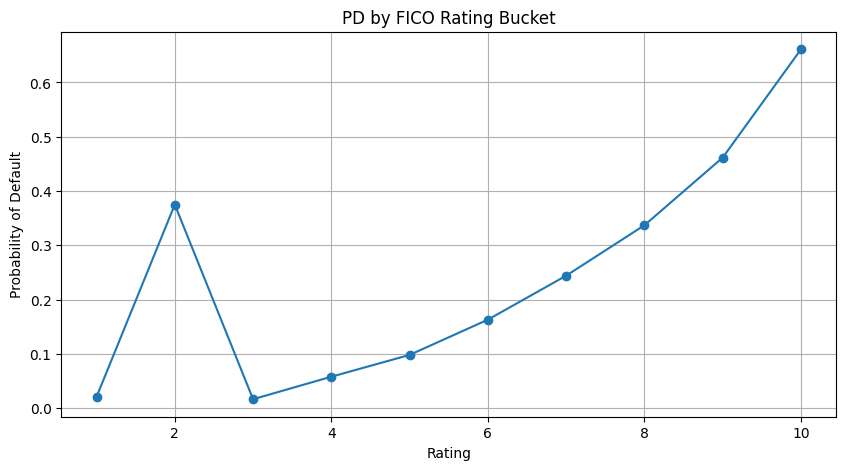

In [31]:
#Visualize the Buckets
plt.figure(figsize=(10,5))

plt.plot(summary.index.astype(int), summary["PD"], marker="o")

plt.xlabel("Rating")
plt.ylabel("Probability of Default")

plt.title("PD by FICO Rating Bucket")

plt.grid(True)

plt.show()